# Dermatology

**Machine Learning · Exercise 0 · Group 56**  
Yazdan ZandiyeVakili · Amir Saadati · Hani Esreb

This notebook describes the disease classes, selected features, and missing
values in [UCI Dermatology (dataset 33)](https://archive.ics.uci.edu/dataset/33/dermatology).
It has fewer records than MembershipWoes, more input features, and six target
classes. Most inputs are ordered scores. We do not train a model here.

## 1. Setup

Run the cells from top to bottom. We used Python 3.12; internet access is
needed to download the data. Install the packages in your notebook environment:

```bash
python -m pip install numpy pandas matplotlib ipykernel jupyterlab
```

Import the libraries and set the plot style. The output records the NumPy and pandas
versions used in this run. The plots stay inside the notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
plt.rcParams.update({'figure.dpi': 150, 'font.size': 10, 'axes.titlesize': 12,
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, TEAL = '#35618D', '#36877E'
print(f'NumPy {np.__version__} | pandas {pd.__version__}')

NumPy 2.3.5 | pandas 2.2.3


## 2. Load the data

Read UCI's CSV directly with pandas. It includes the column names, and missing
ages stay missing.

In [2]:
df = pd.read_csv('https://archive.ics.uci.edu/static/public/33/data.csv')
print(f'{len(df)} patients, {df.shape[1] - 1} inputs, 1 target')

366 patients, 34 inputs, 1 target


## 3. Attribute types

The dataset has 34 inputs: 12 clinical variables and 22 findings from skin
samples. There are 32 ordered scores from 0 to 3. Zero means absent, 3 is the
largest degree, and 1 and 2 are intermediate levels. These are **ordinal** scores:
the order matters, but the gaps between levels are not necessarily equal.

Family history is binary (0 = no reported family history, 1 = a listed disease
in the family). Age is measured in years. Disease codes are category labels.
The table below counts the different input types.

In [3]:
ordinal = df.columns.drop(['family history', 'age', 'class'])
display(pd.Series({'Ordinal scores': len(ordinal), 'Binary family history': 1,
                   'Quantitative age': 1, 'Nominal target': 1}, name='Columns').to_frame())

,Columns
Ordinal scores,32
Binary family history,1
Quantitative age,1
Nominal target,1


## 4. Missing values and age

Count missing values and summarize the ages that are available. Also check
for duplicate rows and zero ages. We keep unusual values for now; the source
says names and patient identifiers were already removed.

In [4]:
missing = pd.DataFrame({'Missing': df.isna().sum(), 'Percent': df.isna().mean() * 100})
display(missing.loc[missing['Missing'] > 0].round(2))
age = df['age'].dropna()
display(age.describe().round(2))
print(f"Complete duplicate rows: {df.duplicated().sum()}; zero ages: {(df['age'] == 0).sum()}")

,Missing,Percent
age,8,2.19


count    358.00
mean      36.30
std       15.32
min        0.00
25%       25.00
50%       35.00
75%       49.75
max       75.00
Name: age, dtype: float64

Complete duplicate rows: 0; zero ages: 1


Eight ages are missing (2.19%). The observed ages range from 0 to 75 years,
with median 35 and quartiles 25 and 49.75. We keep the one zero age because
the source does not explain it. There are no duplicate rows.

## 5. Disease classes and selected distributions

Use UCI's class names to label the six disease codes. Count the patients in
each class and calculate percentages out of all 366 patients.

In [5]:
disease_names = {
    1: 'Psoriasis', 2: 'Seborrhoeic dermatitis', 3: 'Lichen planus',
    4: 'Pityriasis rosea', 5: 'Chronic dermatitis', 6: 'Pityriasis rubra pilaris',
}
class_counts = df['class'].value_counts().sort_index()
class_table = pd.DataFrame({'Disease': pd.Series(disease_names), 'Count': class_counts,
                            'Percent': class_counts / len(df) * 100})
display(class_table.round(2))

,Disease,Count,Percent
1,Psoriasis,112,30.60
2,Seborrhoeic dermatitis,61,16.67
3,Lichen planus,72,19.67
4,Pityriasis rosea,49,13.39
5,Chronic dermatitis,52,14.21
6,Pityriasis rubra pilaris,20,5.46


### Disease and age

Show the class percentages and an age histogram with five-year bins.
PRP stands for pityriasis rubra pilaris. The eight missing ages are left out
of the histogram.

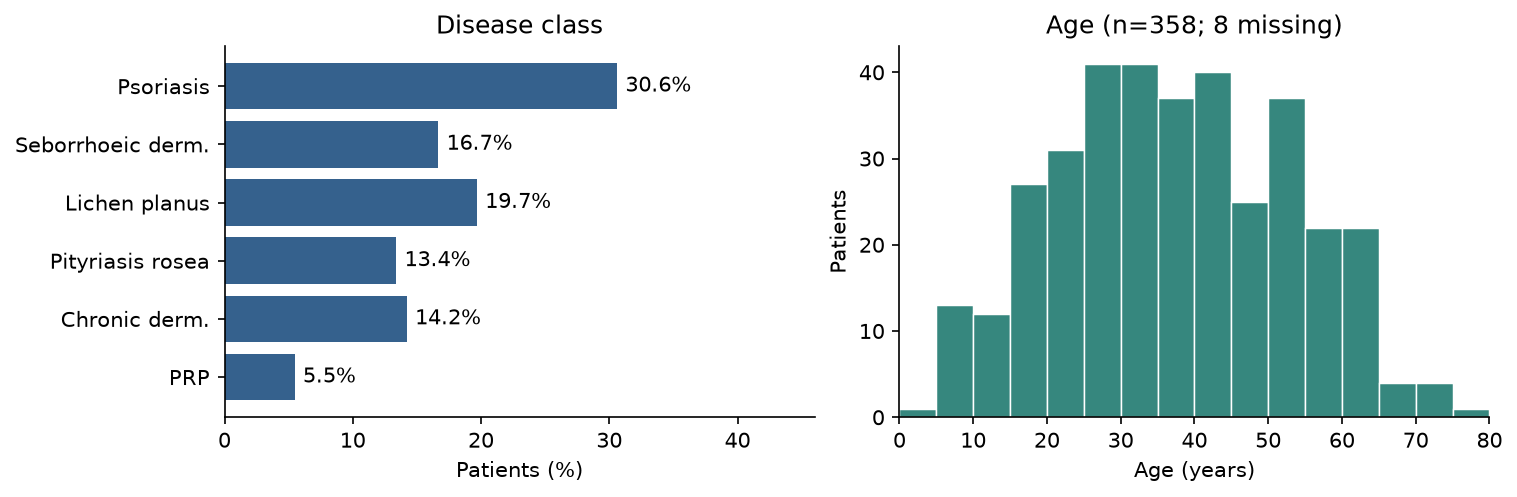

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), layout='constrained')
plot_labels = ['Psoriasis', 'Seborrhoeic derm.', 'Lichen planus',
               'Pityriasis rosea', 'Chronic derm.', 'PRP']
bars = axes[0].barh(plot_labels, class_table['Percent'], color=BLUE)
axes[0].bar_label(bars, fmt='%.1f%%', padding=4)
axes[0].set(xlim=(0, 46), xlabel='Patients (%)', title='Disease class')
axes[0].invert_yaxis()
age_bins = np.arange(0, 81, 5)
axes[1].hist(age, bins=age_bins, color=TEAL, edgecolor='white', linewidth=0.7)
axes[1].set(xlabel='Age (years)', ylabel='Patients', xlim=(0, 80),
            title=f'Age (n={len(age)}; 8 missing)')
plt.show()

Psoriasis is the largest class (112 patients, 30.60%), while PRP is the
smallest (20, 5.46%). That is a 5.6-fold difference. Later evaluation should
keep the class proportions in the data splits and report results for each
class. These dataset counts do not tell us how common the diseases are in
the population.

### Age by disease

Compare ages across the six diseases. The box shows the middle half of the
ages and the line marks the median. Whiskers reach the last observed values
within 1.5 times the interquartile range; dots mark values beyond that.
All observed ages are included, and labels show the number available per class.

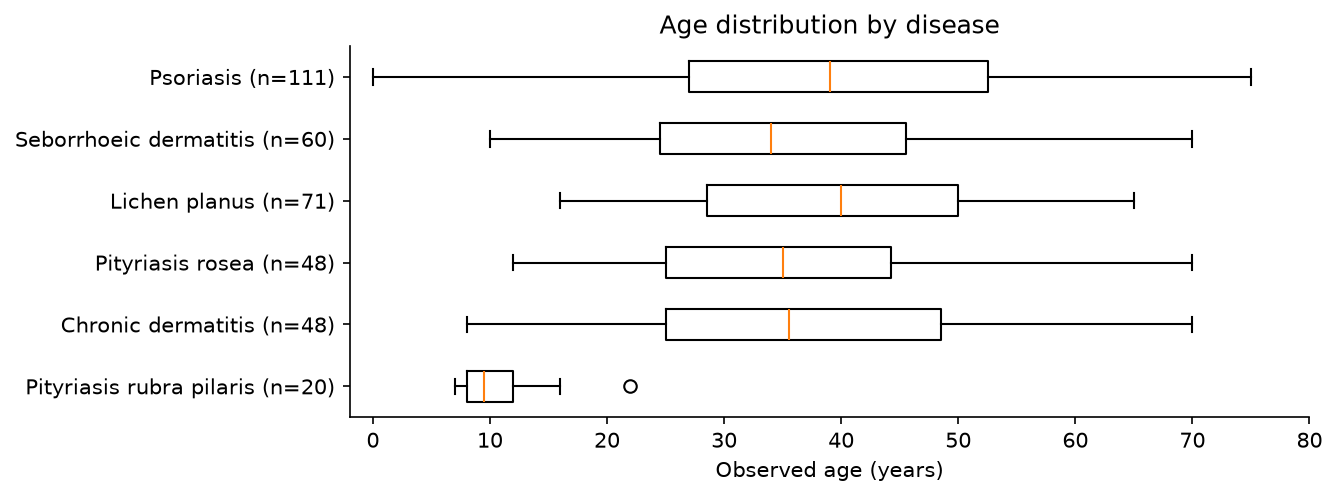

In [7]:
ages_by_disease = [df.loc[df['class'] == code, 'age'].dropna() for code in disease_names]
age_labels = [f'{name} (n={len(ages)})' for name, ages in zip(disease_names.values(), ages_by_disease)]
fig, ax = plt.subplots(figsize=(8.8, 3.2), layout='constrained')
ax.boxplot(ages_by_disease, orientation='horizontal', tick_labels=age_labels)
ax.set(xlim=(-2, 80), xlabel='Observed age (years)', title='Age distribution by disease')
ax.invert_yaxis()
plt.show()

The PRP group is younger in this sample: its median age is 9.5 years,
compared with 34–40 for the other classes. This is a pattern in these data,
not a diagnostic rule.

### Ordinal scores

Compare the first five clinical scores in the source's column order. Each bar
contains all 366 patients, split into degrees 0–3. Labels are shown only for
segments of at least 8% to keep the plot readable. Here, “scaling” means the
skin finding, not rescaling numeric data.

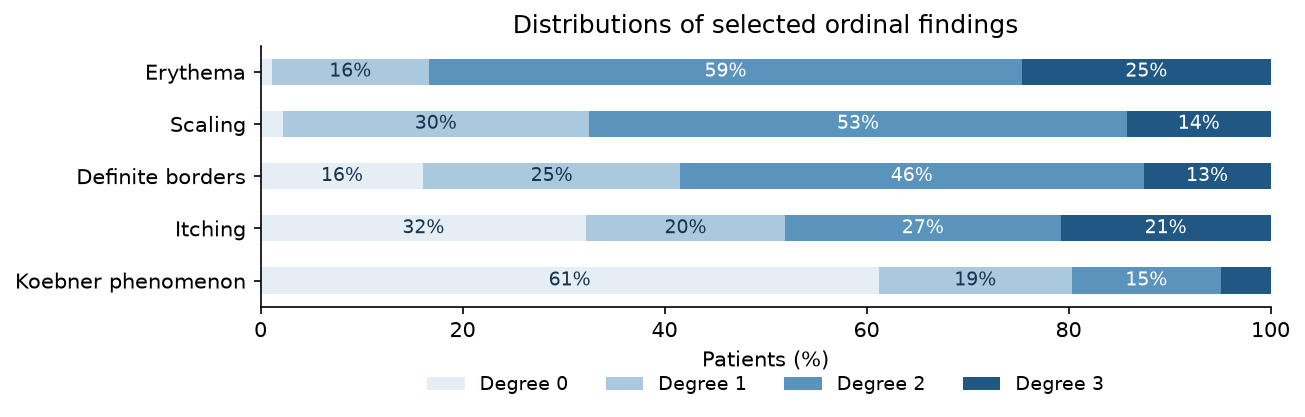

Family history positive: 46 / 366 (12.57%)


In [8]:
features = ['erythema', 'scaling', 'definite-borders', 'itching', 'koebner phenomenon']
score_counts = df[features].apply(pd.Series.value_counts).reindex(range(4)).fillna(0).T
score_percent = score_counts / len(df) * 100
score_percent.index = ['Erythema', 'Scaling', 'Definite borders', 'Itching', 'Koebner phenomenon']
ax = score_percent.plot.barh(stacked=True, figsize=(8.8, 3),
                            color=['#E5EDF5', '#AAC9DF', '#5A93BC', '#205783'])
for level, bars in enumerate(ax.containers):
    labels = [f'{bar.get_width():.0f}%' if bar.get_width() >= 8 else '' for bar in bars]
    ax.bar_label(bars, labels=labels, label_type='center', fontsize=9,
                 color='white' if level >= 2 else '#17364E')
ax.set(xlim=(0, 100), xlabel='Patients (%)', title='Distributions of selected ordinal findings')
ax.invert_yaxis()
ax.legend(['Degree 0', 'Degree 1', 'Degree 2', 'Degree 3'], ncol=4,
          loc='upper center', bbox_to_anchor=(0.5, -0.20), frameon=False, fontsize=9)
plt.tight_layout()
plt.show()
family_counts = df['family history'].value_counts()
print(f"Family history positive: {family_counts[1]} / {len(df)} ({family_counts[1] / len(df) * 100:.2f}%)")

For scaling, degree 2 is the most common score (195 patients, 53.28%).
Degrees 0, 1, and 3 have counts of 8, 111, and 52. Family history is positive
for 46 patients (12.57%).

## Source

Ilter, N., & Guvenir, H. (1998). *Dermatology* [Dataset]. UCI Machine Learning
Repository. [DOI 10.24432/C5FK5P](https://doi.org/10.24432/C5FK5P).
[CSV](https://archive.ics.uci.edu/static/public/33/data.csv) and
[original documentation and data](https://archive.ics.uci.edu/static/public/33/dermatology.zip).
Accessed 24 October 2026; UCI lists the licence as CC BY 4.0.
The report uses these results and the age-by-disease and ordinal-score plots.